<a href="https://colab.research.google.com/github/iqbaal24/PCVK_2026/blob/main/Week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 10 - Dasar-Dasar Deteksi Obyek
Praktikum Pengolahan Citra dan Visi Komputer (Modul 10).


## Setup

In [1]:
import os, glob
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# SESUAIKAN dengan lokasi folder gambar di Drive kamu
BASE = '/content/drive/MyDrive/PCVK/Images'
def P(*parts):
    return os.path.join(BASE, *parts)

def baca(*parts, mode=cv.IMREAD_COLOR):
    img = cv.imread(P(*parts), mode)
    assert img is not None, f'Gambar tidak ditemukan: {P(*parts)}'
    return img

def tampil(img, judul='', size=(8, 6)):
    plt.figure(figsize=size)
    if img.ndim == 2:
        plt.imshow(img, cmap='gray')
    else:
        plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title(judul)
    plt.show()

print(os.listdir(BASE))

['gradient.jpg', 'fingerprint.png', 'leaves.jpg', 'balloon.jpg', 'old_house.jpg', 'testlena.jpg', 'lily.jpg', 'jungle.png', 'testlena2.jpg', 'noisy2.png', 'j.png', 'morphology.png', 'tobacco.jpg', 'peppers.jpg', 'car-park.jpg', 'sudoku.jpg', 'cat-and-rabbit.jpg', 'cats_and_bunnies.jpg', 'parking-lot-cars.jpg', 'crossword.jpg', 'sailboat.tiff', 'cat2_templatejpg.jpg', 'laptop.jpg', 'bahrain.jpg', 'couple.tiff', 'male.tiff', 'bahrain-template.jpg', 'mandrill2.tiff', 'tank.tiff', 'lena_gs_lc.jpg', 'corak.bmp', 'female.tiff', 'kitten01.jpg', 'rose_pink.png', 'wiki.jpg', 'mandrill.tiff', 'teeth.jpg', 'peppers.tiff', 'chess-board.jpg', 'animal.jpg', 'galaxy.jpg', 'people.jpg', 'cat-template.jpg', 'mycat.jpg', 'mjordan.jpg', 'reeses_puffs.png', 'dog.jpg', 'solvayconf.jpg', 'kucing.jpg', 'jokowi.jpg', 'many_cereals.jpg', 'smile.png', 'mask.png', 'kartini.jpg', 'djawatan.jpg', 'prabowo.jpg', 'contoh hasil.png', 'ktp1.jpg', 'Underexposed_photo.JPG', 'sunset.jpg', 'crayfish.jpg', 'crayfish_enhanc

# D1. Praktikum Deteksi Obyek Dasar

## Soal 2 - Template Matching (6 metode OpenCV)

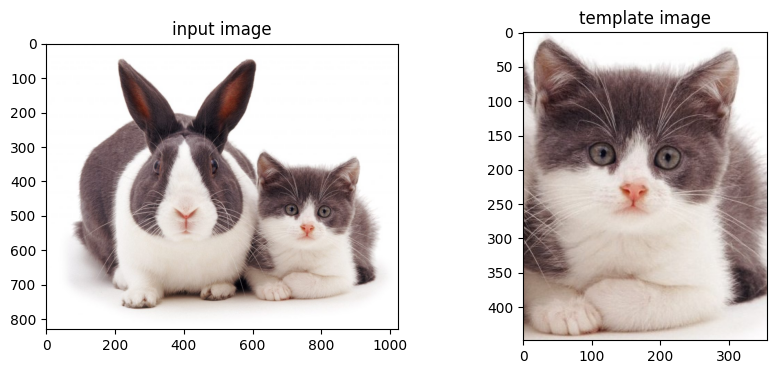

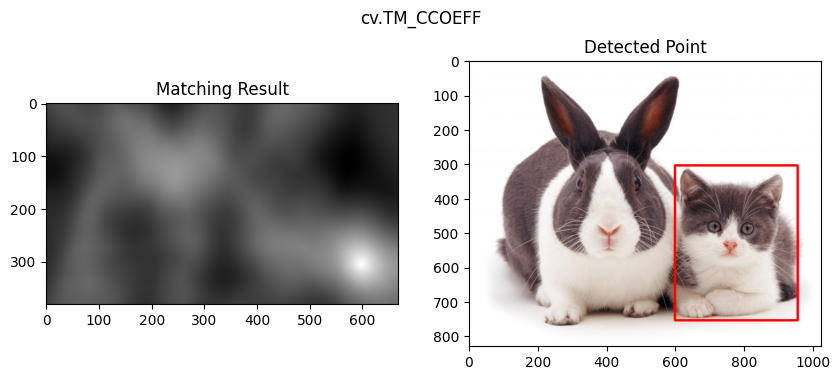

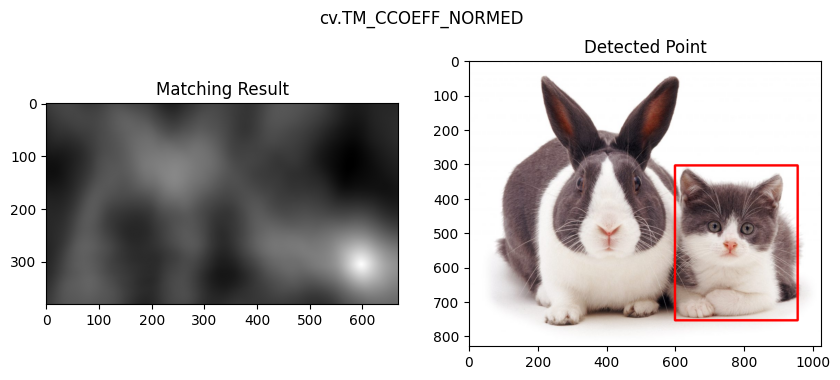

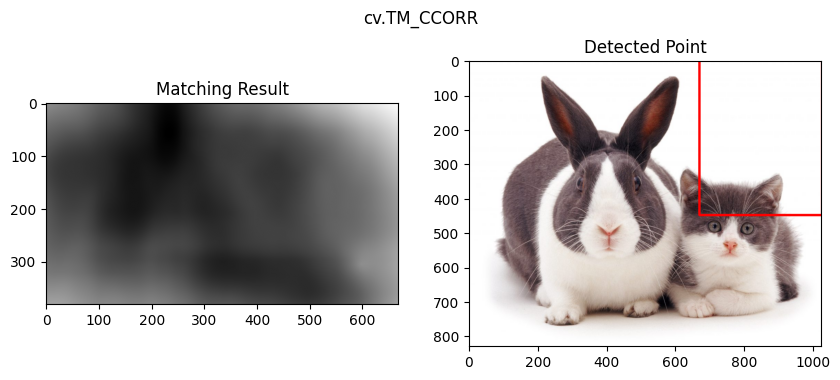

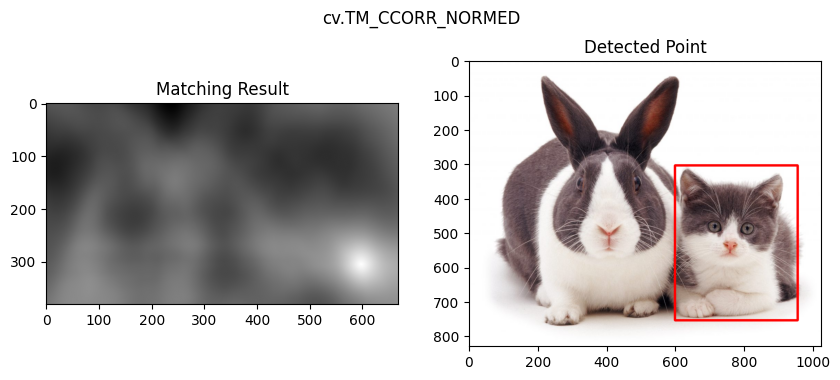

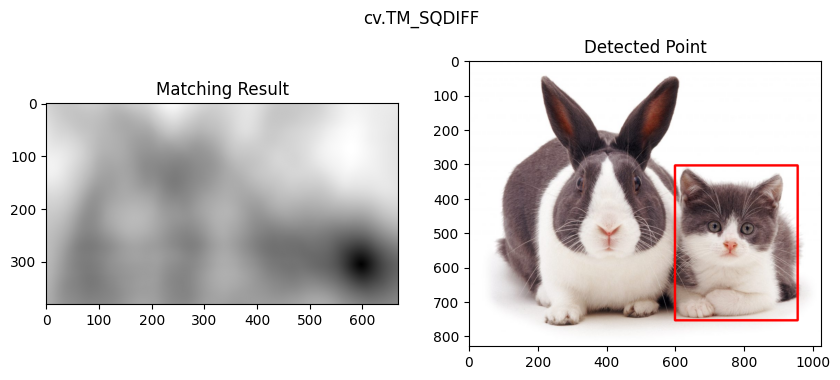

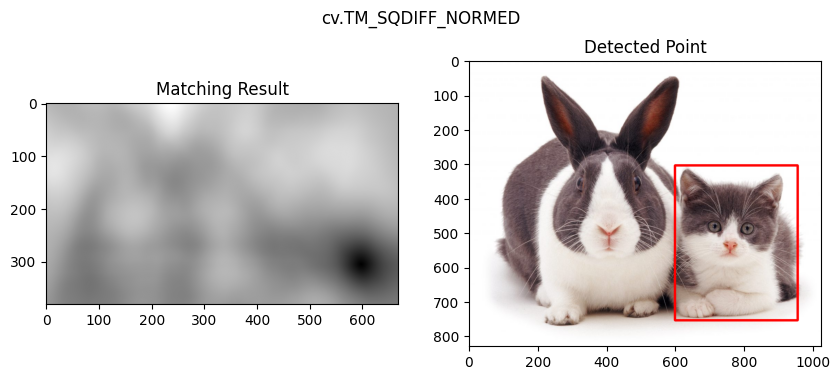

In [3]:
img = baca('cats_and_bunnies.jpg')
template = baca('cat2_templatejpg.jpg')
h, w = template.shape[:2]

plt.figure(figsize=(10, 4))
plt.subplot(121); plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)); plt.title('input image')
plt.subplot(122); plt.imshow(cv.cvtColor(template, cv.COLOR_BGR2RGB)); plt.title('template image')
plt.show()

metode = ['TM_CCOEFF', 'TM_CCOEFF_NORMED', 'TM_CCORR',
          'TM_CCORR_NORMED', 'TM_SQDIFF', 'TM_SQDIFF_NORMED']

for nama in metode:
    m = getattr(cv, nama)
    # Lakukan pencocokan template
    hasil = cv.matchTemplate(img, template, m)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(hasil)

    # Tentukan top_left berdasarkan metode pencarian nilai optimal
    if m in (cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED):
        top_left = min_loc
    else:
        top_left = max_loc

    bottom_right = (top_left[0] + w, top_left[1] + h)

    # Selalu gunakan salinan gambar asli yang bersih
    deteksi = img.copy()
    cv.rectangle(deteksi, top_left, bottom_right, (0, 0, 255), 5)

    plt.figure(figsize=(10, 4))
    plt.suptitle('cv.' + nama)
    plt.subplot(121); plt.imshow(hasil, cmap='gray'); plt.title('Matching Result')
    plt.subplot(122); plt.imshow(cv.cvtColor(deteksi, cv.COLOR_BGR2RGB)); plt.title('Detected Point')
    plt.show()

## Soal 3 - Template Matching tanpa OpenCV (multiple object)
Pencocokan dihitung manual memakai NumPy (korelasi ternormalisasi / ZNCC). OpenCV hanya dipakai untuk membaca gambar.

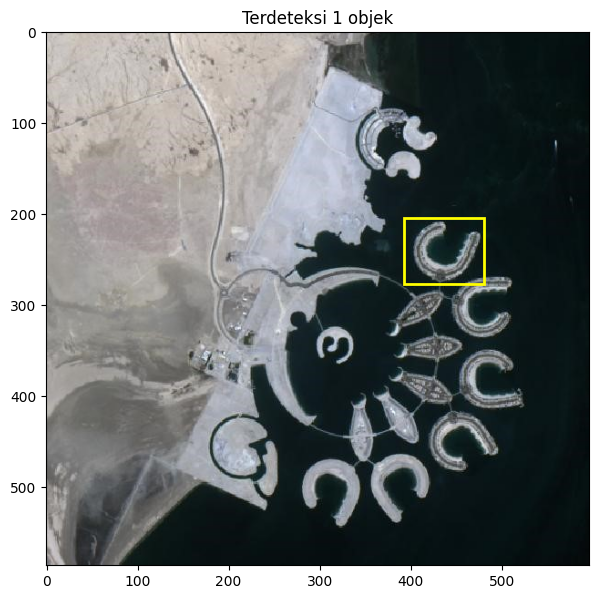

In [4]:
from numpy.lib.stride_tricks import sliding_window_view
import matplotlib.patches as patches

def box_sum(A, h, w):
    # jumlah nilai di setiap jendela h x w memakai integral image
    S = np.pad(A.cumsum(0).cumsum(1), ((1, 0), (1, 0)))
    return S[h:, w:] - S[:-h, w:] - S[h:, :-w] + S[:-h, :-w]

def template_matching_manual(I, T):
    I = I.astype(np.float64); T = T.astype(np.float64)
    h, w = T.shape
    n = h * w
    Tz = T - T.mean()
    t_norm = np.sqrt((Tz ** 2).sum())

    win = sliding_window_view(I, (h, w))                 # semua posisi geser template
    numerator = np.einsum('ijkl,kl->ij', win, Tz)        # sum((I - mean_I) * Tz), karena sum(Tz)=0
    sum_i = box_sum(I, h, w)
    sum_i2 = box_sum(I ** 2, h, w)
    var_i = np.maximum(sum_i2 - (sum_i ** 2) / n, 1e-6)
    return numerator / (np.sqrt(var_i) * t_norm)         # nilai -1 .. 1

img = baca('bahrain.jpg')
tmpl = baca('bahrain-template.jpg')
gray_i = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray_t = cv.cvtColor(tmpl, cv.COLOR_BGR2GRAY) if tmpl.ndim == 3 else tmpl
h, w = gray_t.shape

R = template_matching_manual(gray_i, gray_t)

threshold = 0.6   # naikkan jika terlalu banyak kotak, turunkan jika ada yang terlewat
R_kerja = R.copy()
kotak = []
while True:
    y, x = np.unravel_index(np.argmax(R_kerja), R_kerja.shape)
    if R_kerja[y, x] < threshold:
        break
    kotak.append((x, y))
    # hapus area sekitar agar objek yang sama tidak terdeteksi dua kali
    R_kerja[max(0, y - h // 2): y + h // 2, max(0, x - w // 2): x + w // 2] = -1

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
for (x, y) in kotak:
    ax.add_patch(patches.Rectangle((x, y), w, h, edgecolor='yellow', facecolor='none', linewidth=2))
ax.set_title(f'Terdeteksi {len(kotak)} objek')
plt.show()

## Soal 4 - Sobel, Canny, dan Laplacian Edge Detection

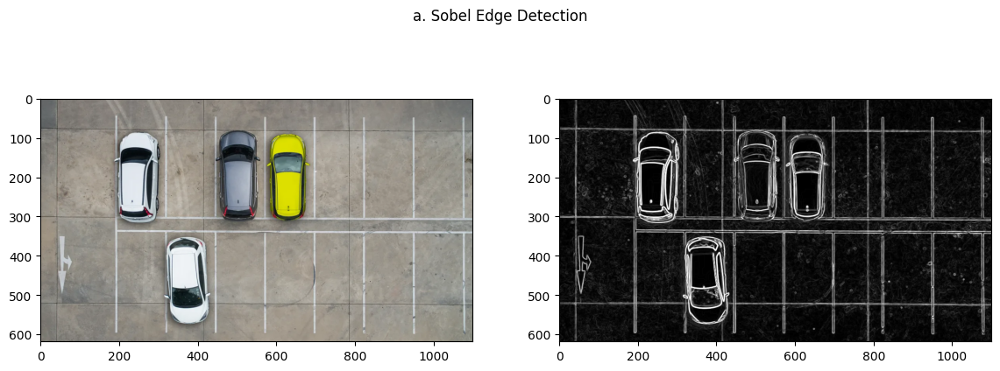

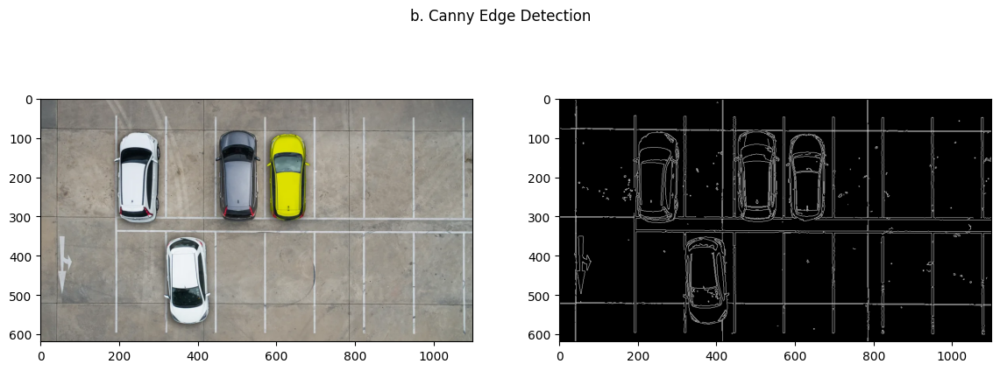

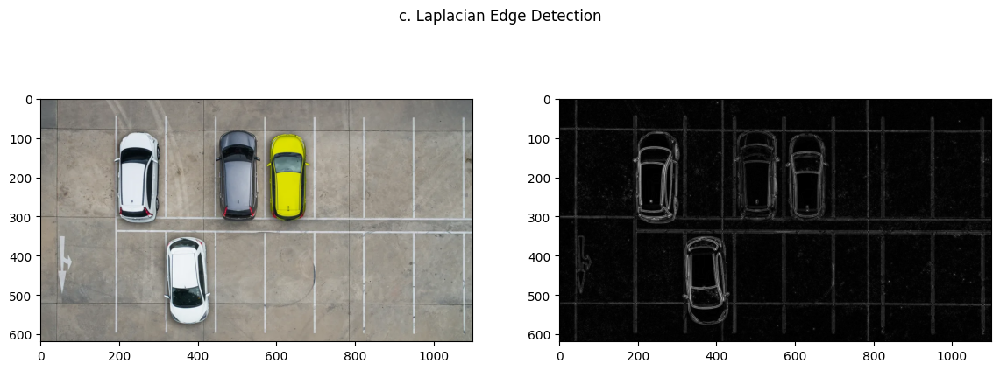

In [5]:
img = baca('car-park.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

def pasangan(hasil, judul):
    plt.figure(figsize=(14, 5))
    plt.suptitle(judul)
    plt.subplot(121); plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.subplot(122); plt.imshow(hasil, cmap='gray')
    plt.show()

# a. Sobel
blur = cv.GaussianBlur(gray, (3, 3), 0)
sobel_x = cv.Sobel(blur, cv.CV_64F, 1, 0, ksize=3)
sobel_y = cv.Sobel(blur, cv.CV_64F, 0, 1, ksize=3)
sobel = cv.convertScaleAbs(np.sqrt(sobel_x ** 2 + sobel_y ** 2))
pasangan(sobel, 'a. Sobel Edge Detection')

# b. Canny
canny = cv.Canny(gray, 100, 200)
pasangan(canny, 'b. Canny Edge Detection')

# c. Laplacian (dihaluskan dulu dengan Gaussian karena sensitif noise)
blur5 = cv.GaussianBlur(gray, (5, 5), 0)
laplacian = cv.convertScaleAbs(cv.Laplacian(blur5, cv.CV_64F, ksize=3))
pasangan(laplacian, 'c. Laplacian Edge Detection')

## Soal 5 - Harris Corner dan Shi-Tomasi

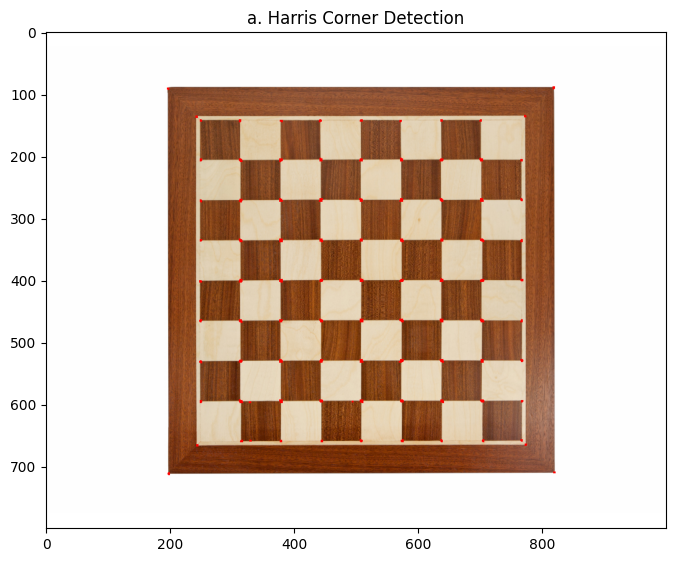

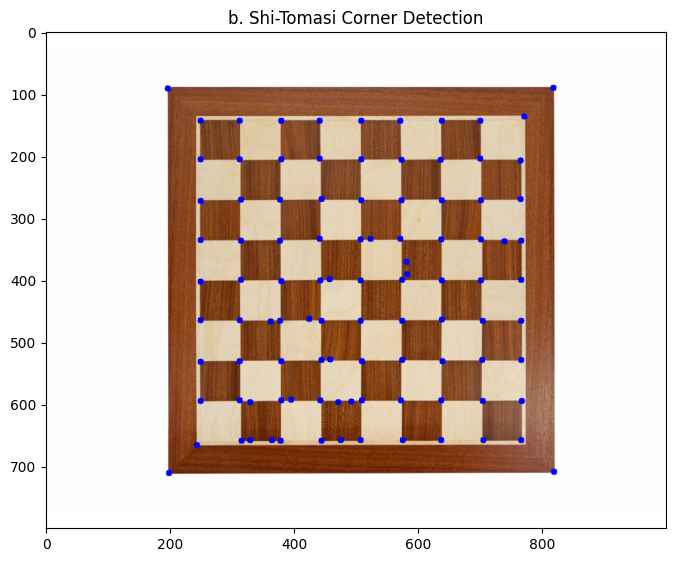

In [6]:
img = baca('chess-board.jpg')   # sesuaikan nama file (chess-board.jpg / chessboard.jpg)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# a. Harris Corner Detection
harris = cv.cornerHarris(np.float32(gray), blockSize=2, ksize=3, k=0.04)
harris = cv.dilate(harris, None)
hasil_harris = img.copy()
hasil_harris[harris > 0.01 * harris.max()] = [0, 0, 255]
tampil(hasil_harris, 'a. Harris Corner Detection', (8, 8))

# b. Shi-Tomasi
sudut = cv.goodFeaturesToTrack(gray, maxCorners=100, qualityLevel=0.01, minDistance=10)
sudut = np.int32(sudut)
hasil_shi = img.copy()
for s in sudut:
    x, y = s.ravel()
    cv.circle(hasil_shi, (int(x), int(y)), 5, (255, 0, 0), -1)
tampil(hasil_shi, 'b. Shi-Tomasi Corner Detection', (8, 8))

## Soal 6 - Grid Detection dengan Hough Transform
Tahapan: Canny, dilasi, erosi, HoughLines, lalu garis yang mirip digabung.

Jumlah garis sebelum digabung: 56
Jumlah garis setelah digabung: 14


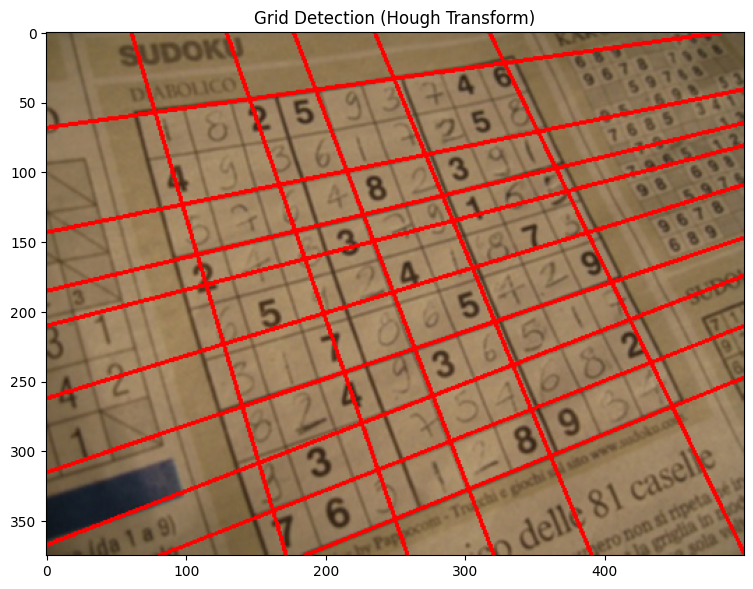

In [7]:
img = baca('sudoku.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
blur = cv.GaussianBlur(gray, (5, 5), 0)

edges = cv.Canny(blur, 50, 150)                       # 1. Canny
kernel = np.ones((3, 3), np.uint8)
dilasi = cv.dilate(edges, kernel, iterations=1)       # 2. Dilasi
erosi = cv.erode(dilasi, kernel, iterations=1)        # 3. Erosi
# 4. Menaikkan threshold HoughLines secara signifikan untuk menyaring hanya garis yang sangat kuat
lines = cv.HoughLines(erosi, 1, np.pi / 180, 200)
print('Jumlah garis sebelum digabung:', len(lines))

def gabung_garis(lines, rho_thr=35, theta_thr=np.deg2rad(15)):
    # 5. Menggabungkan garis dengan rentang toleransi rho dan theta yang lebih longgar agar bersih
    klaster = []
    for rho, theta in lines[:, 0]:
        if rho < 0:
            rho, theta = -rho, theta - np.pi

        tergabung = False
        for k in klaster:
            diff_rho = abs(k['rho'] - rho)
            diff_theta = abs(k['theta'] - theta)
            if diff_theta > np.pi / 2:
                diff_theta = abs(diff_theta - np.pi)

            if diff_rho < rho_thr and diff_theta < theta_thr:
                k['list'].append((rho, theta))
                k['rho'] = np.mean([a for a, b in k['list']])
                k['theta'] = np.mean([b for a, b in k['list']])
                tergabung = True
                break
        if not tergabung:
            klaster.append({'rho': rho, 'theta': theta, 'list': [(rho, theta)]})
    return [(k['rho'], k['theta']) for k in klaster]

garis = gabung_garis(lines)
print('Jumlah garis setelah digabung:', len(garis))

hasil = img.copy()
for rho, theta in garis:
    a, b = np.cos(theta), np.sin(theta)
    x0, y0 = a * rho, b * rho
    p1 = (int(x0 + 2000 * (-b)), int(y0 + 2000 * a))
    p2 = (int(x0 - 2000 * (-b)), int(y0 - 2000 * a))
    cv.line(hasil, p1, p2, (0, 0, 255), 2)
tampil(hasil, 'Grid Detection (Hough Transform)', (9, 7))

## Soal 7 - Contour Detection

Jumlah kontur: 19


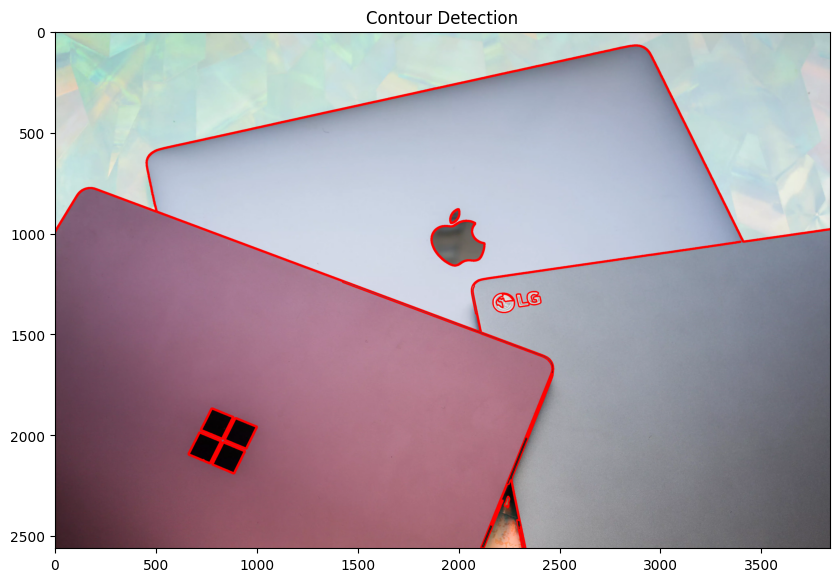

In [8]:
img = baca('laptop.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
blur = cv.GaussianBlur(gray, (7, 7), 0)

# ubah ke citra biner (edge) dulu agar kontur lebih akurat
edges = cv.Canny(blur, 30, 100)
edges = cv.dilate(edges, np.ones((3, 3), np.uint8), iterations=2)

kontur, hierarki = cv.findContours(edges, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)
kontur_besar = [c for c in kontur if cv.contourArea(c) > 500]   # buang kontur noise yang kecil
print('Jumlah kontur:', len(kontur_besar))

hasil = img.copy()
cv.drawContours(hasil, kontur_besar, -1, (0, 0, 255), 5)
tampil(hasil, 'Contour Detection', (10, 7))

# D2. Praktikum Feature Matching dan Face Detection

## Soal 8 - Face Detection pada semua gambar di folder facedet

Daftar file gambar wajah yang akan diproses: ['lena.jpg', 'testlena.jpg', 'testlena2.jpg', 'mjordan.jpg', 'prabowo.jpg']


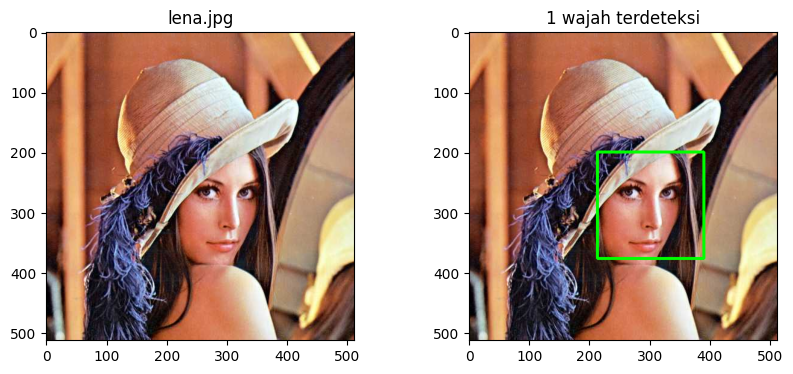

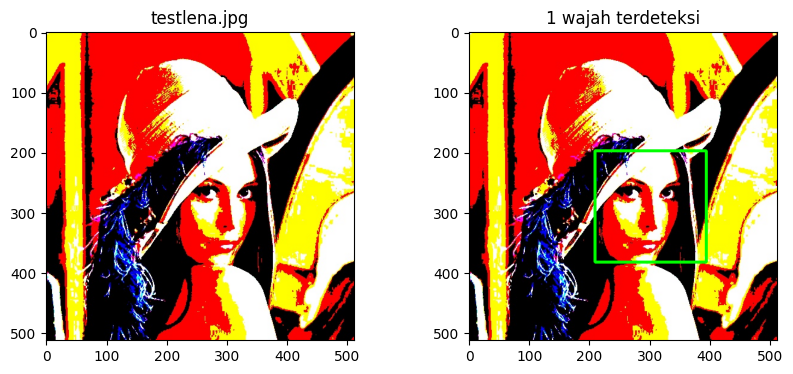

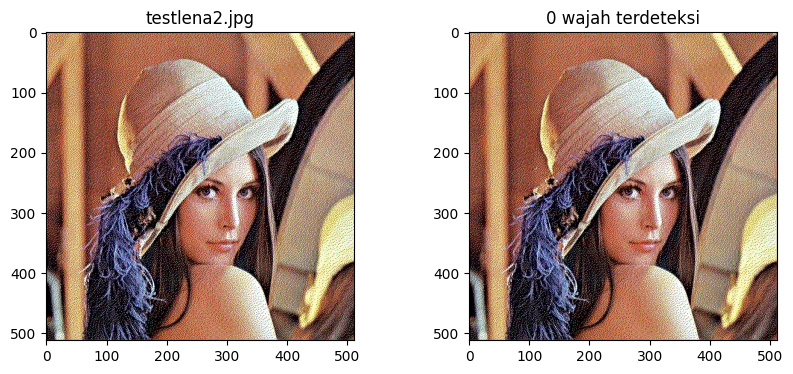

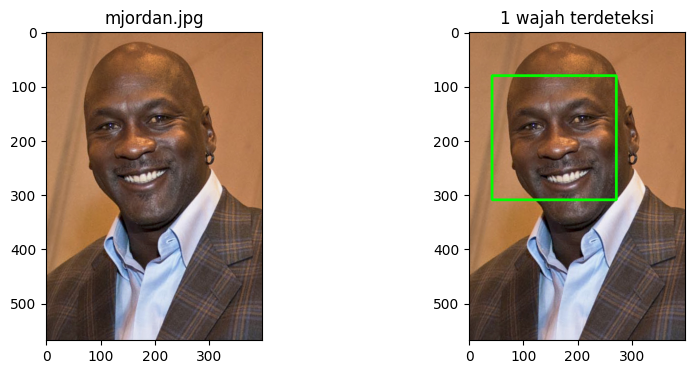

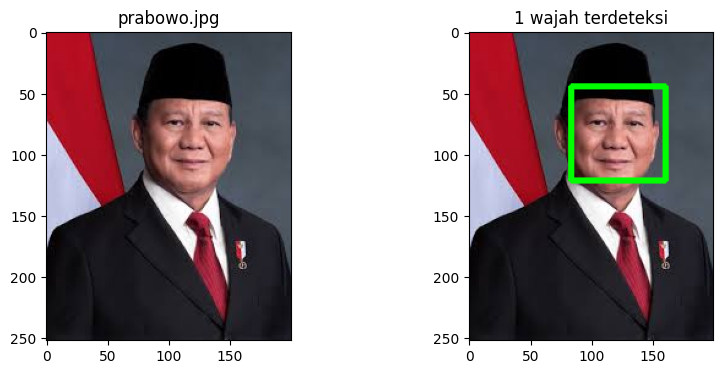

In [9]:
import os, glob
import cv2 as cv
from matplotlib import pyplot as plt

# Memastikan fungsi pembantu P ada jika sel setup terlewat
if 'P' not in globals():
    BASE = '/content/drive/MyDrive/PCVK/Images'
    def P(*parts):
        return os.path.join(BASE, *parts)

cascade_wajah = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalface_alt.xml')

# Mencari di folder facedet
daftar = sorted(f for f in glob.glob(P('facedet', '*')) if f.lower().endswith(('.jpg', '.jpeg', '.png')))

# FALLBACK: Jika folder facedet kosong, gunakan gambar wajah dari folder utama Images
if not daftar:
    pilihan_fallback = ['lena.jpg', 'testlena.jpg', 'testlena2.jpg', 'mjordan.jpg', 'prabowo.jpg']
    daftar = [P(f) for f in pilihan_fallback if os.path.exists(P(f))]

print("Daftar file gambar wajah yang akan diproses:", [os.path.basename(f) for f in daftar])

for f in daftar:
    asli = cv.imread(f)
    if asli is None:
        continue
    gray = cv.cvtColor(asli, cv.COLOR_BGR2GRAY)
    wajah = cascade_wajah.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))
    hasil = asli.copy()
    for (x, y, w, h) in wajah:
        cv.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), 3)

    plt.figure(figsize=(10, 4))
    plt.subplot(121); plt.imshow(cv.cvtColor(asli, cv.COLOR_BGR2RGB)); plt.title(os.path.basename(f))
    plt.subplot(122); plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB)); plt.title(f'{len(wajah)} wajah terdeteksi')
    plt.show()

## Soal 9 - Deteksi Wajah Kucing
OpenCV menyediakan cascade khusus kucing: `haarcascade_frontalcatface_extended.xml`.

Daftar file gambar kucing yang akan diproses: ['cats_and_bunnies.jpg', 'cat2_templatejpg.jpg', 'kitten01.jpg']


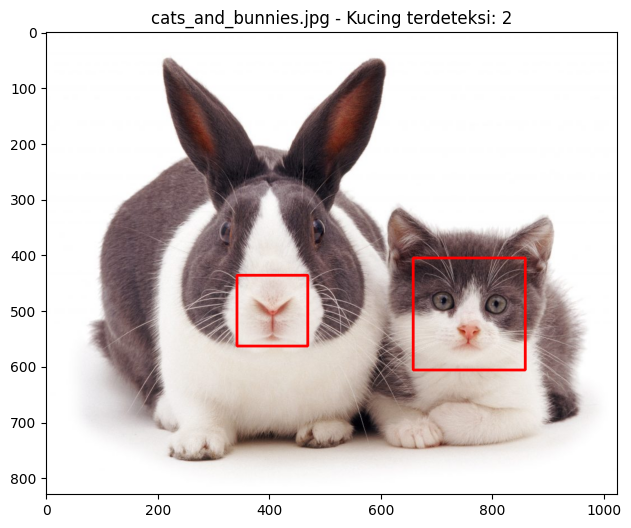

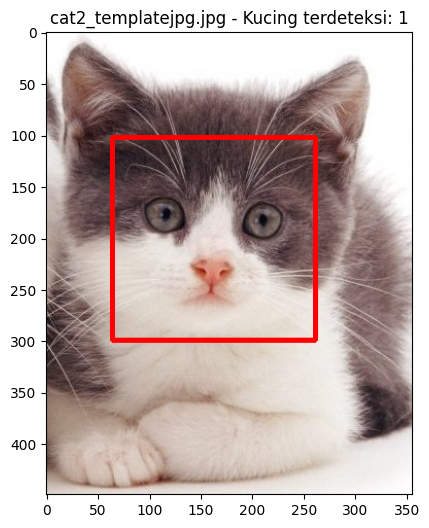

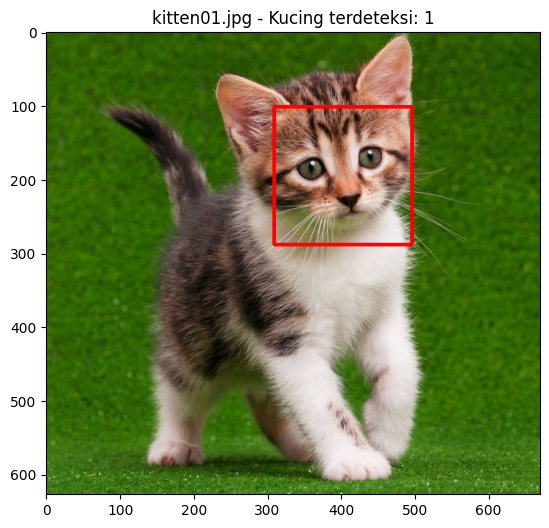

In [10]:
cascade_kucing = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalcatface_extended.xml')

# Mencari file kucing di daftar atau folder utama Images
file_kucing = [f for f in daftar if 'cat' in os.path.basename(f).lower() or 'kucing' in os.path.basename(f).lower()]

# FALLBACK: Jika kosong, gunakan gambar yang mengandung kucing seperti 'cats_and_bunnies.jpg'
if not file_kucing:
    fallback_kucing = ['cats_and_bunnies.jpg', 'cat2_templatejpg.jpg', 'kitten01.jpg']
    file_kucing = [P(f) for f in fallback_kucing if os.path.exists(P(f))]

print("Daftar file gambar kucing yang akan diproses:", [os.path.basename(f) for f in file_kucing])

for f in file_kucing:
    asli = cv.imread(f)
    if asli is None:
        continue
    gray = cv.cvtColor(asli, cv.COLOR_BGR2GRAY)
    kucing = cascade_kucing.detectMultiScale(gray, scaleFactor=1.05, minNeighbors=3, minSize=(50, 50))
    hasil = asli.copy()
    for (x, y, w, h) in kucing:
        cv.rectangle(hasil, (x, y), (x + w, y + h), (0, 0, 255), 3)

    plt.figure(figsize=(8, 6))
    plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB))
    plt.title(f'{os.path.basename(f)} - Kucing terdeteksi: {len(kucing)}')
    plt.show()

## Soal 10 - Eyes Detection pada wajah Pak Prabowo

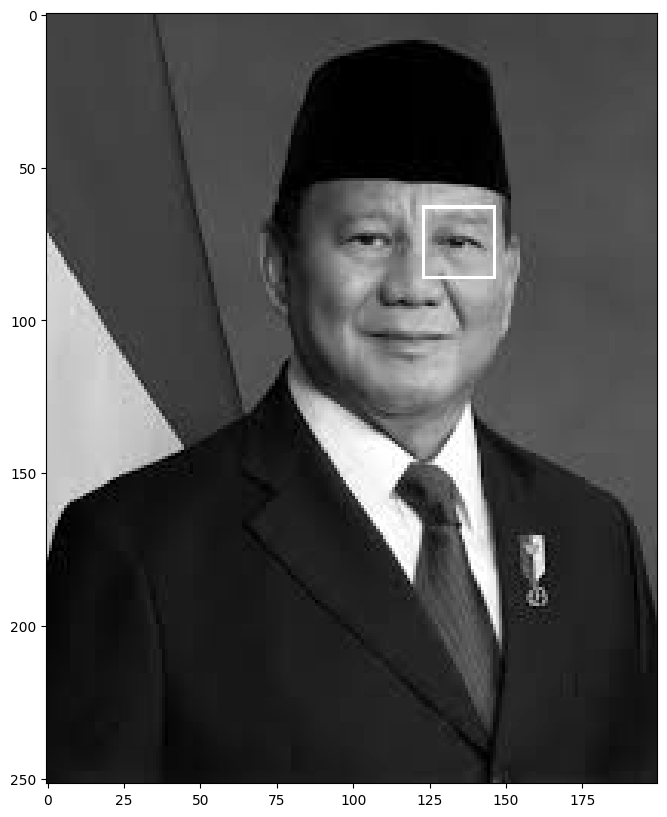

In [11]:
cascade_mata = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_eye.xml')

# Using the custom 'baca' helper to load as grayscale and throw a clear error if the file is missing
prabowo = baca('prabowo.jpg', mode=cv.IMREAD_GRAYSCALE)
hasil = prabowo.copy()
for (fx, fy, fw, fh) in cascade_wajah.detectMultiScale(prabowo):
    roi = prabowo[fy:fy + fh, fx:fx + fw]            # cari mata hanya di dalam wajah
    for (ex, ey, ew, eh) in cascade_mata.detectMultiScale(roi):
        cv.rectangle(hasil, (fx + ex, fy + ey), (fx + ex + ew, fy + ey + eh), 255, 1)
plt.figure(figsize=(10, 10)); plt.imshow(hasil, cmap='gray'); plt.show()

## Soal 11 - Deteksi Senyuman pada gambar people

Jumlah senyum terdeteksi: 0


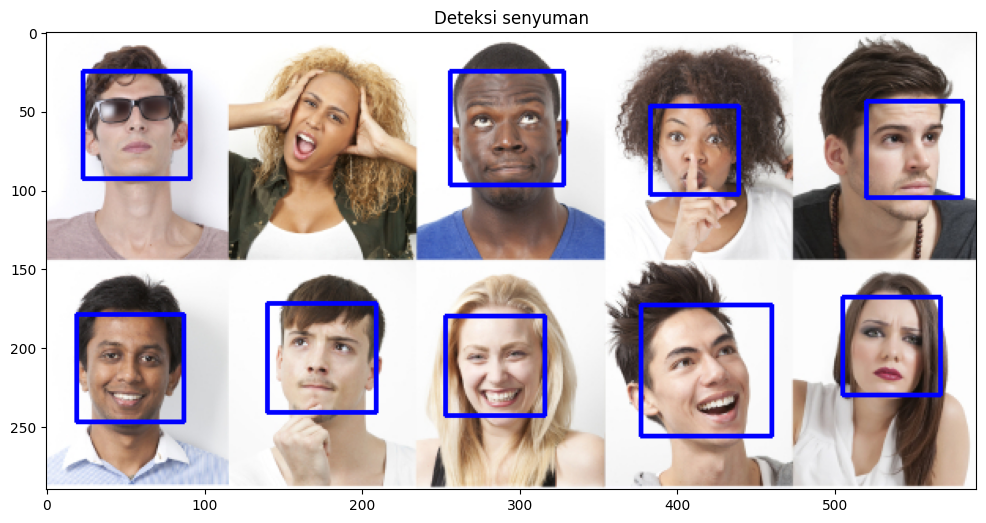

In [12]:
cascade_senyum = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_smile.xml')

people = baca('people.jpg')   # sesuaikan nama file
gray = cv.cvtColor(people, cv.COLOR_BGR2GRAY)
hasil = people.copy()
jumlah_senyum = 0
for (x, y, w, h) in cascade_wajah.detectMultiScale(gray):
    cv.rectangle(hasil, (x, y), (x + w, y + h), (255, 0, 0), 2)
    # senyum dicari di setengah bawah wajah saja supaya tidak salah deteksi
    roi = gray[y + h // 2: y + h, x: x + w]
    for (sx, sy, sw, sh) in cascade_senyum.detectMultiScale(roi, scaleFactor=1.7, minNeighbors=20):
        cv.rectangle(hasil, (x + sx, y + h // 2 + sy), (x + sx + sw, y + h // 2 + sy + sh), (0, 255, 0), 2)
        jumlah_senyum += 1
print('Jumlah senyum terdeteksi:', jumlah_senyum)
tampil(hasil, 'Deteksi senyuman', (12, 6))

## Soal 12 - Face Tracking dengan kamera di Google Colab
Jalankan dua sel di bawah ini, lalu izinkan akses kamera di browser. Klik video untuk berhenti.

In [13]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode, b64encode
import PIL.Image, io

def video_stream():
    js = Javascript('''
    var video; var div = null; var stream; var captureCanvas; var imgElement; var labelElement;
    var pendingResolve = null; var shutdown = false;
    function removeDom() {
      stream.getVideoTracks()[0].stop(); video.remove(); div.remove();
      video = null; div = null; stream = null; imgElement = null; captureCanvas = null; labelElement = null;
    }
    function onAnimationFrame() {
      if (!shutdown) { window.requestAnimationFrame(onAnimationFrame); }
      if (pendingResolve) {
        var result = "";
        if (!shutdown) { captureCanvas.getContext('2d').drawImage(video, 0, 0, 640, 480); result = captureCanvas.toDataURL('image/jpeg', 0.8); }
        var lp = pendingResolve; pendingResolve = null; lp(result);
      }
    }
    async function createDom() {
      if (div !== null) { return stream; }
      div = document.createElement('div');
      div.style.border = '2px solid black'; div.style.padding = '3px'; div.style.width = '100%'; div.style.maxWidth = '600px';
      document.body.appendChild(div);
      const modelOut = document.createElement('div');
      modelOut.innerHTML = "<span>Status:</span>";
      labelElement = document.createElement('span'); labelElement.innerText = 'No data'; labelElement.style.fontWeight = 'bold';
      modelOut.appendChild(labelElement); div.appendChild(modelOut);
      video = document.createElement('video'); video.style.display = 'block'; video.width = div.clientWidth - 6;
      video.setAttribute('playsinline', ''); video.onclick = () => { shutdown = true; };
      stream = await navigator.mediaDevices.getUserMedia({video: { facingMode: "user"}});
      div.appendChild(video);
      imgElement = document.createElement('img'); imgElement.style.position = 'absolute'; imgElement.style.zIndex = 1;
      imgElement.onclick = () => { shutdown = true; }; div.appendChild(imgElement);
      const instruction = document.createElement('div');
      instruction.innerHTML = '<span style="color: red; font-weight: bold;">Klik di sini atau pada video untuk berhenti</span>';
      div.appendChild(instruction); instruction.onclick = () => { shutdown = true; };
      video.srcObject = stream; await video.play();
      captureCanvas = document.createElement('canvas'); captureCanvas.width = 640; captureCanvas.height = 480;
      window.requestAnimationFrame(onAnimationFrame);
      return stream;
    }
    async function stream_frame(label, imgData) {
      if (shutdown) { removeDom(); shutdown = false; return ''; }
      stream = await createDom();
      if (label != "") { labelElement.innerHTML = label; }
      if (imgData != "") {
        var videoRect = video.getClientRects()[0];
        imgElement.style.top = videoRect.top + "px"; imgElement.style.left = videoRect.left + "px";
        imgElement.style.width = videoRect.width + "px"; imgElement.style.height = videoRect.height + "px";
        imgElement.src = imgData;
      }
      var result = await new Promise(function(resolve, reject) { pendingResolve = resolve; });
      shutdown = false;
      return {'img': result};
    }
    ''')
    display(js)

def video_frame(label, bbox):
    return eval_js('stream_frame("{}", "{}")'.format(label, bbox))

def js_to_image(js_reply):
    image_bytes = b64decode(js_reply.split(',')[1])
    return cv.imdecode(np.frombuffer(image_bytes, dtype=np.uint8), flags=1)

def bbox_to_bytes(bbox_array):
    iobuf = io.BytesIO()
    PIL.Image.fromarray(bbox_array, 'RGBA').save(iobuf, format='png')
    return 'data:image/png;base64,{}'.format(str(b64encode(iobuf.getvalue()), 'utf-8'))

In [15]:
video_stream()
label_html = 'Mendeteksi wajah...'
bbox = ''
while True:
    js_reply = video_frame(label_html, bbox)
    if not js_reply:
        break
    frame = js_to_image(js_reply['img'])
    gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
    wajah = cascade_wajah.detectMultiScale(gray)

    overlay = np.zeros([480, 640, 4], dtype=np.uint8)   # lapisan transparan untuk kotak
    for (x, y, w, h) in wajah:
        overlay = cv.rectangle(overlay, (x, y), (x + w, y + h), (255, 0, 0), 2)
    overlay[:, :, 3] = (overlay.max(axis=2) > 0) * 255
    bbox = bbox_to_bytes(overlay)

<IPython.core.display.Javascript object>

/tmp/ipykernel_3202/4027565744.py:71: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  PIL.Image.fromarray(bbox_array, 'RGBA').save(iobuf, format='png')


## Soal 13 - Blurring pada wajah yang terdeteksi

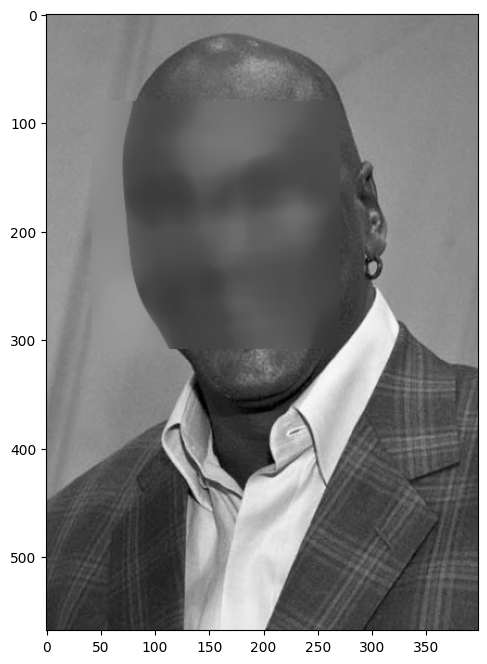

In [16]:
nama_file = 'mjordan.jpg'   # ganti dengan nama file foto di folder facedet
foto = cv.imread(P(nama_file))
gray = cv.cvtColor(foto, cv.COLOR_BGR2GRAY)

hasil = gray.copy()
for (x, y, w, h) in cascade_wajah.detectMultiScale(gray):
    hasil[y:y + h, x:x + w] = cv.medianBlur(hasil[y:y + h, x:x + w], 51)   # ukuran kernel harus ganjil
plt.figure(figsize=(6, 8)); plt.imshow(hasil, cmap='gray'); plt.show()

## Soal 14 - Mengolah gambar KTM masing-masing
Siapkan foto KTM milikmu (`ktm.jpg`) dan foto KTM yang diletakkan bersama barang lain (`ktm_scene.jpg`) di folder Images.

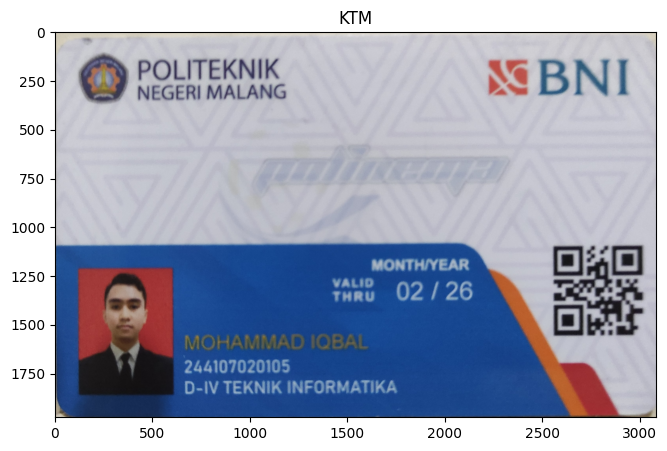

In [17]:
# a. tampilkan KTM
ktm = baca('ktm.jpg')
tampil(ktm, 'KTM', (8, 5))

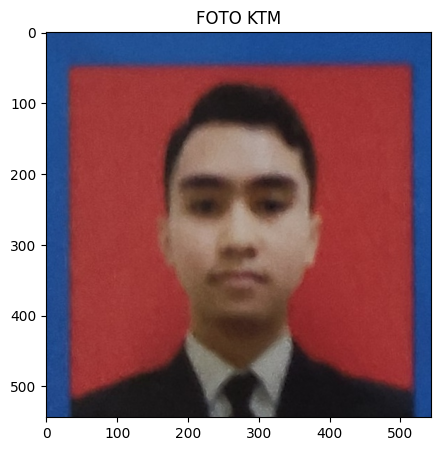

In [18]:
# b. ambil foto dari KTM dengan face detection (kotak wajah diperlebar sedikit agar rambut/jilbab ikut)
gray = cv.cvtColor(ktm, cv.COLOR_BGR2GRAY)
wajah = cascade_wajah.detectMultiScale(gray, 1.1, 4)
assert len(wajah) > 0, 'Wajah tidak terdeteksi. Pakai crop manual: foto_ktm = ktm[y1:y2, x1:x2]'
x, y, w, h = max(wajah, key=lambda f: f[2] * f[3])
pad = int(0.5 * w)
foto_ktm = ktm[max(0, y - pad): y + h + pad, max(0, x - pad): x + w + pad]
tampil(foto_ktm, 'FOTO KTM', (5, 5))

Jumlah good matches: 1373


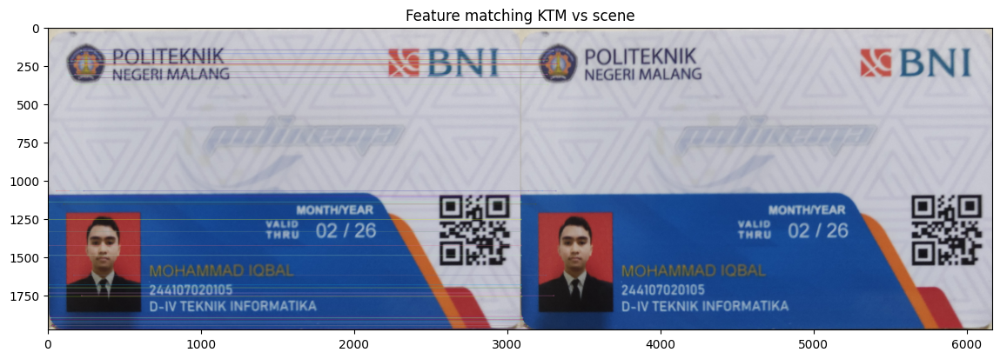

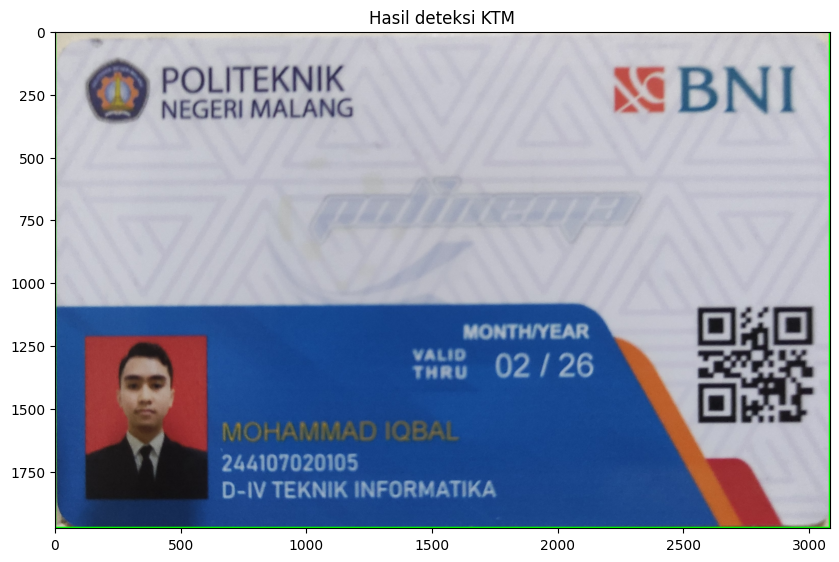

In [19]:
# c. deteksi KTM pada gambar yang berisi barang lain dengan Feature Matching (SIFT + ratio test + homography)
scene = baca('ktm.jpg')
g_ktm = cv.cvtColor(ktm, cv.COLOR_BGR2GRAY)
g_scene = cv.cvtColor(scene, cv.COLOR_BGR2GRAY)

sift = cv.SIFT_create()
kp1, des1 = sift.detectAndCompute(g_ktm, None)
kp2, des2 = sift.detectAndCompute(g_scene, None)

bf = cv.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)
good = [m for m, n in matches if m.distance < 0.75 * n.distance]
print('Jumlah good matches:', len(good))

hasil_scene = scene.copy()
if len(good) >= 10:
    src = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    M, mask = cv.findHomography(src, dst, cv.RANSAC, 5.0)
    h, w = g_ktm.shape
    sudut = np.float32([[0, 0], [0, h - 1], [w - 1, h - 1], [w - 1, 0]]).reshape(-1, 1, 2)
    kotak = cv.perspectiveTransform(sudut, M)
    hasil_scene = cv.polylines(hasil_scene, [np.int32(kotak)], True, (0, 255, 0), 8)
else:
    print('Kecocokan kurang, KTM tidak ditemukan.')

garis_match = cv.drawMatches(ktm, kp1, scene, kp2, good[:50], None, flags=2)
tampil(garis_match, 'Feature matching KTM vs scene', (14, 6))
tampil(hasil_scene, 'Hasil deteksi KTM', (10, 7))

# D3. Tugas Pengayaan - Pengenalan Karakter KTM dengan CNN

Siapkan dataset dulu (crop manual satu per satu dengan image editor):

`dataset/training/0`, `dataset/training/1`, ... `dataset/training/9` (tiap folder berisi gambar angka tersebut)

`dataset/testing/ktm/` berisi gambar tiap karakter NIM di KTM kamu, **urutannya sesuai nama file** (misal `01.png`, `02.png`, ...)

Folder `dataset` ditaruh di `/content` (atau pindah ke Drive lalu ubah `DATADIR`).

In [20]:
# OPSIONAL: potong otomatis angka NIM dari gambar bagian NIM saja (hasil crop manual 1 baris NIM)
# untuk dijadikan data testing. Hasilnya diurutkan dari kiri ke kanan.
# Hubungkan dengan helper 'baca' agar mengambil file dari Google Drive Anda
nim = baca('KTM1b.jpg', mode=cv.IMREAD_GRAYSCALE) # Ganti 'KTM1b.jpg' dengan nama file crop manual 1 baris NIM Anda
_, bw = cv.threshold(nim, 0, 255, cv.THRESH_BINARY_INV + cv.THRESH_OTSU)
if bw.mean() > 127:          # pastikan karakter berwarna putih di latar hitam
    bw = 255 - bw
kontur, _ = cv.findContours(bw, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
kotak = sorted([cv.boundingRect(c) for c in kontur if cv.contourArea(c) > 30], key=lambda b: b[0])

os.makedirs('dataset/testing/ktm', exist_ok=True)
for i, (x, y, w, h) in enumerate(kotak, start=1):
    cv.imwrite(f'dataset/testing/ktm/{i:02d}.png', bw[y:y + h, x:x + w])
print('Karakter terpotong:', len(kotak))

Karakter terpotong: 135


### Persiapan data training

In [25]:
import os
import cv2
import numpy as np
import pickle
import kagglehub

# Download versi terbaru dari dataset MNIST
path_download = kagglehub.dataset_download("hichamachahboun/mnist-handwritten-digits")
print("Path to dataset files:", path_download)

# Load langsung file .npy dari path download
train_images_path = os.path.join(path_download, 'train_images.npy')
train_labels_path = os.path.join(path_download, 'train_labels.npy')

if os.path.exists(train_images_path) and os.path.exists(train_labels_path):
    print("Memuat data dari file NumPy...")
    images = np.load(train_images_path)
    labels = np.load(train_labels_path)

    # Batasi jumlah data (misal 5000 gambar) agar proses resize cepat dan ramah memori
    limit = 5000
    images = images[:limit]
    labels = labels[:limit]

    width, height = 100, 100
    X = []

    print("Mengubah ukuran gambar ke 100x100...")
    for img in images:
        # Resize gambar dari ukuran asli (biasanya 28x28) ke 100x100
        resized = cv2.resize(img, (width, height))
        X.append(resized)

    X = np.array(X).reshape(-1, width, height, 1)
    Y = np.array(labels)

    # Daftar kelas unik
    dirs = [str(i) for i in sorted(np.unique(Y))]

    # Simpan ke file pickle
    pickle.dump(X, open("X.pickle", "wb"))
    pickle.dump(Y, open("Y.pickle", "wb"))
    pickle.dump(dirs, open("kelas.pickle", "wb"))

    print("Proses selesai!")
    print("Jumlah data :", len(X))
    print("Jumlah kelas:", len(dirs), dirs)
else:
    print("Error: File npy tidak ditemukan di folder download!")

Using Colab cache for faster access to the 'mnist-handwritten-digits' dataset.
Path to dataset files: /kaggle/input/mnist-handwritten-digits
Memuat data dari file NumPy...
Mengubah ukuran gambar ke 100x100...
Proses selesai!
Jumlah data : 5000
Jumlah kelas: 10 ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


### Training data (CNN)

In [26]:
import pickle
from keras.layers import (Input, Conv2D, MaxPooling2D,
                          Flatten, Dense, ZeroPadding2D)
from keras.models import Model
from keras.optimizers import Adam
from keras.utils import to_categorical

X = pickle.load(open("X.pickle", "rb"))
Y = pickle.load(open("Y.pickle", "rb"))

Y = to_categorical(Y)
X = X / 255.0
width, height = 100, 100
jumlah_kelas = Y.shape[1]        # diambil dari data, tidak ditulis tetap

inputs     = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten   = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64,  activation='relu')(fc_layer)
outputs  = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

riwayat = model.fit(X, Y, epochs=20, verbose=1, validation_split=0.2)
model.save('anpr.keras')

print("akurasi training  :", riwayat.history['accuracy'][-1])
print("akurasi validasi  :", riwayat.history['val_accuracy'][-1])

Epoch 1/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 91s 714ms/step - accuracy: 0.8070 - loss: 0.6928 - val_accuracy: 0.9240 - val_loss: 0.2908
Epoch 2/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 91s 726ms/step - accuracy: 0.9342 - loss: 0.2286 - val_accuracy: 0.9390 - val_loss: 0.2065
Epoch 3/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 85s 678ms/step - accuracy: 0.9635 - loss: 0.1298 - val_accuracy: 0.9360 - val_loss: 0.2166
Epoch 4/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 141s 669ms/step - accuracy: 0.9747 - loss: 0.0827 - val_accuracy: 0.9540 - val_loss: 0.1615
Epoch 5/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 88s 699ms/step - accuracy: 0.9835 - loss: 0.0493 - val_accuracy: 0.9490 - val_loss: 0.1841
Epoch 6/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 83s 662ms/step - accuracy: 0.9925 - loss: 0.0256 - val_accuracy: 0.9560 - val_loss: 0.1658
Epoch 7/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 83s 663ms/step - accuracy: 0.9960 - loss: 0.0176 - val_accuracy: 0.9530 - val_loss: 0.1771
Epoch 8/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 147s 698ms/step - accuracy: 0.9985 - loss:

### Testing data

In [27]:
import os
import cv2
import pickle
import numpy as np
import tensorflow as tf

data_dir_testing = "dataset/testing"
width, height = 100, 100

model = tf.keras.models.load_model("anpr.keras")
dirs  = pickle.load(open("kelas.pickle", "rb"))    # urutan kelas saat training

for car in sorted(os.listdir(data_dir_testing)):
    temp = ""
    folder = os.path.join(data_dir_testing, car)
    for char_img in sorted(os.listdir(folder)):
        img_array = cv2.imread(os.path.join(folder, char_img),
                               cv2.IMREAD_GRAYSCALE)
        new_array = cv2.resize(img_array, (width, height))
        new_array = new_array.reshape(-1, width, height, 1) / 255.0
        prediction = model.predict(new_array, verbose=0)
        temp += dirs[np.argmax(prediction[0])]
    print("folder name: {} no: {}".format(car, temp))

folder name: ktm no: 826884482008086658888802826858688888208258380888882840180383328280888882202882030892892028053288028268280002806808620883608880008008884
